In [1]:
from typing import Literal, Optional
from langgraph.graph import StateGraph, MessagesState, END
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.checkpoint.memory import MemorySaver
import os
from dotenv import load_dotenv
load_dotenv()

GROQ_API_KEY=os.getenv('GROQ_API_KEY')

C:\Users\Syed Ameer Baji\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
model = ChatGroq(model="openai/gpt-oss-120b", temperature=0)

In [3]:
class DraftReviewState(MessagesState):
    human_request: str
    human_comment: Optional[str]
    status: Literal["approved", "feedback"]
    assistant_response: str

In [4]:
def assistant_draft(state: DraftReviewState) -> DraftReviewState:
    user_message = HumanMessage(content=state["human_request"])
    status = state.get("status", "approved")

    if (status == "feedback" and state.get("human_comment")):
        human_comment = HumanMessage(content=state["human_comment"])
                
        # this is the feedback revision step, where the assistant revises its previous draft
        #  it combines feedback from the human with its previous messages to generate a new, improved response.
        system_message = SystemMessage(content=(f"""
        You are an AI assistant revising your previous draft. Carefully review the human's 
        feedback and update your reply accordingly. Address all comments, corrections, 
        or suggestions provided by the human. Ensure your revised response fully 
        integrates the feedback, improves clarity, and resolves any issues raised.
        """))

        messages = [user_message] + state["messages"] + [system_message, human_comment]
        all_messages = state["messages"] + [human_comment]

    else:        
        # this is the initial draft generation step, 
        # where the assistant creates a response based on the user's request 
        # without any prior feedback.
        system_message = SystemMessage(content=("""
        You are an AI assistant. Your goal is to fully understand and fulfill the user's 
        request by preparing a relevant, clear, and helpful draft reply. Focus on addressing 
        the user's needs directly and comprehensively. 
        Do not reference any previous human feedback at this stage.
        """))
        messages = [system_message, user_message]
        all_messages = state["messages"] # get all the previous messages from the state
    
    response = model.invoke(messages)

    all_messages = all_messages + [response] # updating with the model response 

    # here we will pass this to other nodes 
    return {
        **state,
        "messages": all_messages,
        "assistant_response": response.content #type : ignore
    }

def human_feedback(state: DraftReviewState):
    pass

In [5]:
def assistant_finalize(state: DraftReviewState) -> DraftReviewState:
    system_message = """
    You are an AI assistant. The user has approved your draft. Carefully 
    review your reply and make any final improvements to clarity, tone, and 
    completeness. Ensure the response is polished, professional, and ready 
    to be delivered as the final answer.
    """
    messages = [system_message] + state["messages"]
    response = model.invoke(messages)

    all_messages = state['messages'] + [response]

    return {
        **state,
        "messages": all_messages,
        "assistant_response": response.content
    }

In [6]:
def feedback_router(state: DraftReviewState) -> str:
    if state['status'] == 'approved':
        return 'assistant_finalize'
    else:
        return 'assistant_draft'

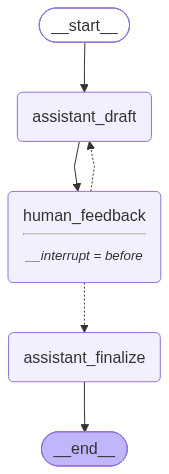

In [7]:
builder = StateGraph(DraftReviewState)

# builder.add_node('start', start_node)
builder.add_node('assistant_draft', assistant_draft)
builder.add_node('human_feedback', human_feedback)
builder.add_node('assistant_finalize', assistant_finalize)

builder.set_entry_point('assistant_draft')
builder.add_edge('assistant_draft', 'human_feedback')
builder.add_conditional_edges(
    'human_feedback', 
    feedback_router, {
        'assistant_draft': 'assistant_draft',
        'assistant_finalize': "assistant_finalize"
        }
    )
builder.add_edge('assistant_finalize', END)

memory = MemorySaver()
graph = builder.compile(interrupt_before=["human_feedback"], checkpointer=memory)
graph

In [8]:
config = {
    "configurable": {
        "thread_id": "1"
    }
}

res = graph.invoke(input={"human_request": "What is the capital of France?"}, config=config)
res

{'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.082977263, 'prompt_time': 0.005981854, 'queue_time': 0.153953425, 'total_time': 0.088959117, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--9941c962-1475-4f5f-bab2-22ad1add7ed0-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180})],
 'human_request': 'What is the capital of France?',
 'assistant_response': 'The capital of France is **Paris**.'}

In [9]:
from pprint import pprint


state = graph.get_state(config=config)
pprint(state)

StateSnapshot(values={'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.082977263, 'prompt_time': 0.005981854, 'queue_time': 0.153953425, 'total_time': 0.088959117, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--9941c962-1475-4f5f-bab2-22ad1add7ed0-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180})], 'human_request': 'What is the capital of France?', 'assistant_response': 'The capital of France is **Paris**.'}, next=('human_feedback',), config={'configurable': {'thread_id': '1', 'che

In [10]:
graph.update_state(config,
                   {"human_comment": "Please provide more details about the capital city.", 
                            "status": "feedback"
                            }
                   )

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e184e-e082-6c3f-8002-b636e2bc358d'}}

In [11]:
new = graph.invoke(None , config=config)

In [12]:
new

{'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.082977263, 'prompt_time': 0.005981854, 'queue_time': 0.153953425, 'total_time': 0.088959117, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--9941c962-1475-4f5f-bab2-22ad1add7ed0-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180}),
  HumanMessage(content='Please provide more details about the capital city.', additional_kwargs={}, response_metadata={}, id='13700a30-0d19-49a8-bcbe-7342a137d6d5'),
  AIMessage(content='**Paris – The Capital

In [16]:
a = graph.update_state(config, {"status": "approved"})
a =graph.invoke(None , config=config)

In [17]:
a

{'messages': [AIMessage(content='The capital of France is **Paris**.', additional_kwargs={'reasoning_content': 'The user asks: "What is the capital of France?" Straightforward answer: Paris. Provide answer.'}, response_metadata={'token_usage': {'completion_tokens': 40, 'prompt_tokens': 140, 'total_tokens': 180, 'completion_time': 0.082977263, 'prompt_time': 0.005981854, 'queue_time': 0.153953425, 'total_time': 0.088959117, 'completion_tokens_details': {'reasoning_tokens': 22}}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_c15aa9c1b7', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--9941c962-1475-4f5f-bab2-22ad1add7ed0-0', usage_metadata={'input_tokens': 140, 'output_tokens': 40, 'total_tokens': 180}),
  HumanMessage(content='Please provide more details about the capital city.', additional_kwargs={}, response_metadata={}, id='13700a30-0d19-49a8-bcbe-7342a137d6d5'),
  AIMessage(content='**Paris – The Capital